# COVID-19 in India: Analysis and Visualization

**Questions**
1. Which states have the most confirmed cases?
2. Which states have the most deaths?
3. Which states have the highest death rate?
4. How did daily new cases change over time?

**Important:** `Confirmed`, `Cured` and `Deaths` are **running totals**, not daily numbers. So comparisons between states use only the latest date, and daily cases are found with `diff()`.

## 1. Setup

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme()
Path("../images").mkdir(exist_ok=True)   # make sure the charts have a folder to be saved in

## 2. Load the Cleaned Data

In [2]:
df = pd.read_csv("../data/clean.csv", parse_dates=["Date"])
print(df.shape)
df.head()

(18046, 5)


,Date,State/UnionTerritory,Cured,Deaths,Confirmed
0,2020-01-30,Kerala,0,0,1
1,2020-01-31,Kerala,0,0,1
2,2020-02-01,Kerala,0,0,2
3,2020-02-02,Kerala,0,0,3
4,2020-02-03,Kerala,0,0,3


## 3. Interpretation and Findings

### Question 1: Which states have the most confirmed cases?

**What I noticed:** The `Confirmed` column is a running total, not the cases for one day. Each row adds to the one before it.

**What I did:** Because of this, I can't add up all the rows. I kept only the latest date, so each state has one row with its final total.

In [3]:
latest = df[df["Date"] == df["Date"].max()].copy()
as_of = latest["Date"].max().strftime("%d %b %Y")   # used in the chart titles

print("Latest date:", as_of)
print("States/UTs:", len(latest))

Latest date: 11 Aug 2021
States/UTs: 36


In [4]:
most_cases_states = latest.sort_values("Confirmed", ascending=False).head(5)
most_cases_states

,Date,State/UnionTerritory,Cured,Deaths,Confirmed
18030,2021-08-11,Maharashtra,6159676,134201,6363442
18026,2021-08-11,Kerala,3396184,18004,3586693
18025,2021-08-11,Karnataka,2861499,36848,2921049
18040,2021-08-11,Tamil Nadu,2524400,34367,2579130
18011,2021-08-11,Andhra Pradesh,1952736,13564,1985182


**Finding:** Maharashtra has the most cases (6.36M), far ahead of Kerala in second place (3.59M).

### Question 2: Which states have the most deaths?

**What I noticed:** `Deaths` is also a running total, so I used the latest date again.

**What I did:** I sorted all 36 states by `Deaths` and kept the top 5.

In [5]:
most_deaths_states = latest.sort_values("Deaths", ascending=False).head(5)
most_deaths_states

,Date,State/UnionTerritory,Cured,Deaths,Confirmed
18030,2021-08-11,Maharashtra,6159676,134201,6363442
18025,2021-08-11,Karnataka,2861499,36848,2921049
18040,2021-08-11,Tamil Nadu,2524400,34367,2579130
18018,2021-08-11,Delhi,1411280,25068,1436852
18044,2021-08-11,Uttar Pradesh,1685492,22775,1708812


**Finding:** Maharashtra is #1 in deaths (134,201), far above #2 Karnataka (36,848). Kerala has the 2nd most cases but is not in the top 5 for deaths, while Delhi and Uttar Pradesh are. So the order by cases is not the same as the order by deaths.

### Question 3: Which states have the highest death rate?

**What I noticed:** Deaths and Confirmed are both running totals, so I used the latest date. The death rate is Deaths divided by Confirmed, times 100.

**What I did:** I made a new column, `Death_rate`, for all 36 states and sorted it from highest to lowest.

In [6]:
latest["Death_rate"] = latest["Deaths"] / latest["Confirmed"] * 100

highest_rate_states = latest.sort_values("Death_rate", ascending=False).head(5)
highest_rate_states[["State/UnionTerritory", "Confirmed", "Deaths", "Death_rate"]]

,State/UnionTerritory,Confirmed,Deaths,Death_rate
18037,Punjab,599573,16322,2.722271
18043,Uttarakhand,342462,7368,2.151480
18030,Maharashtra,6363442,134201,2.108937
18034,Nagaland,28811,585,2.030474
18019,Goa,172085,3164,1.838626


**Finding:** Punjab has the highest recorded death rate (2.72%), followed by Uttarakhand (2.15%). Maharashtra is #1 in deaths but only #3 in death rate (2.11%). So having the most deaths does not mean having the highest rate.

**Note:** This is a recorded rate, so it depends on how many cases were detected. It does not prove one state is more dangerous than another.

### Question 4: How did daily new cases change over time?

**What I noticed:** Adding all states on one date gives India's running total for that date. The difference between one day and the day before is the number of new cases on that day.

**What I did:** I summed `Confirmed` by date, then used `diff()` to get the daily new cases.

In [7]:
india = df.groupby("Date")["Confirmed"].sum()
daily_cases = india.diff()

peak_date = daily_cases.idxmax()
peak_value = daily_cases.max()
print(f"Highest day overall: {peak_date:%d %b %Y} with {peak_value:,.0f} new cases")

first_wave = daily_cases[:"2020-12-31"]
print(f"First-wave peak:     {first_wave.idxmax():%d %b %Y} with {first_wave.max():,.0f} new cases")

Highest day overall: 07 May 2021 with 414,188 new cases
First-wave peak:     17 Sep 2020 with 97,894 new cases


**Finding:** There were two waves. The first peaked on 17 Sep 2020 at about 98,000 new cases a day. The second was much bigger and peaked on 7 May 2021 at 414,188 new cases a day.

## 4. Visualization

### Question 1: Top 5 states by confirmed cases

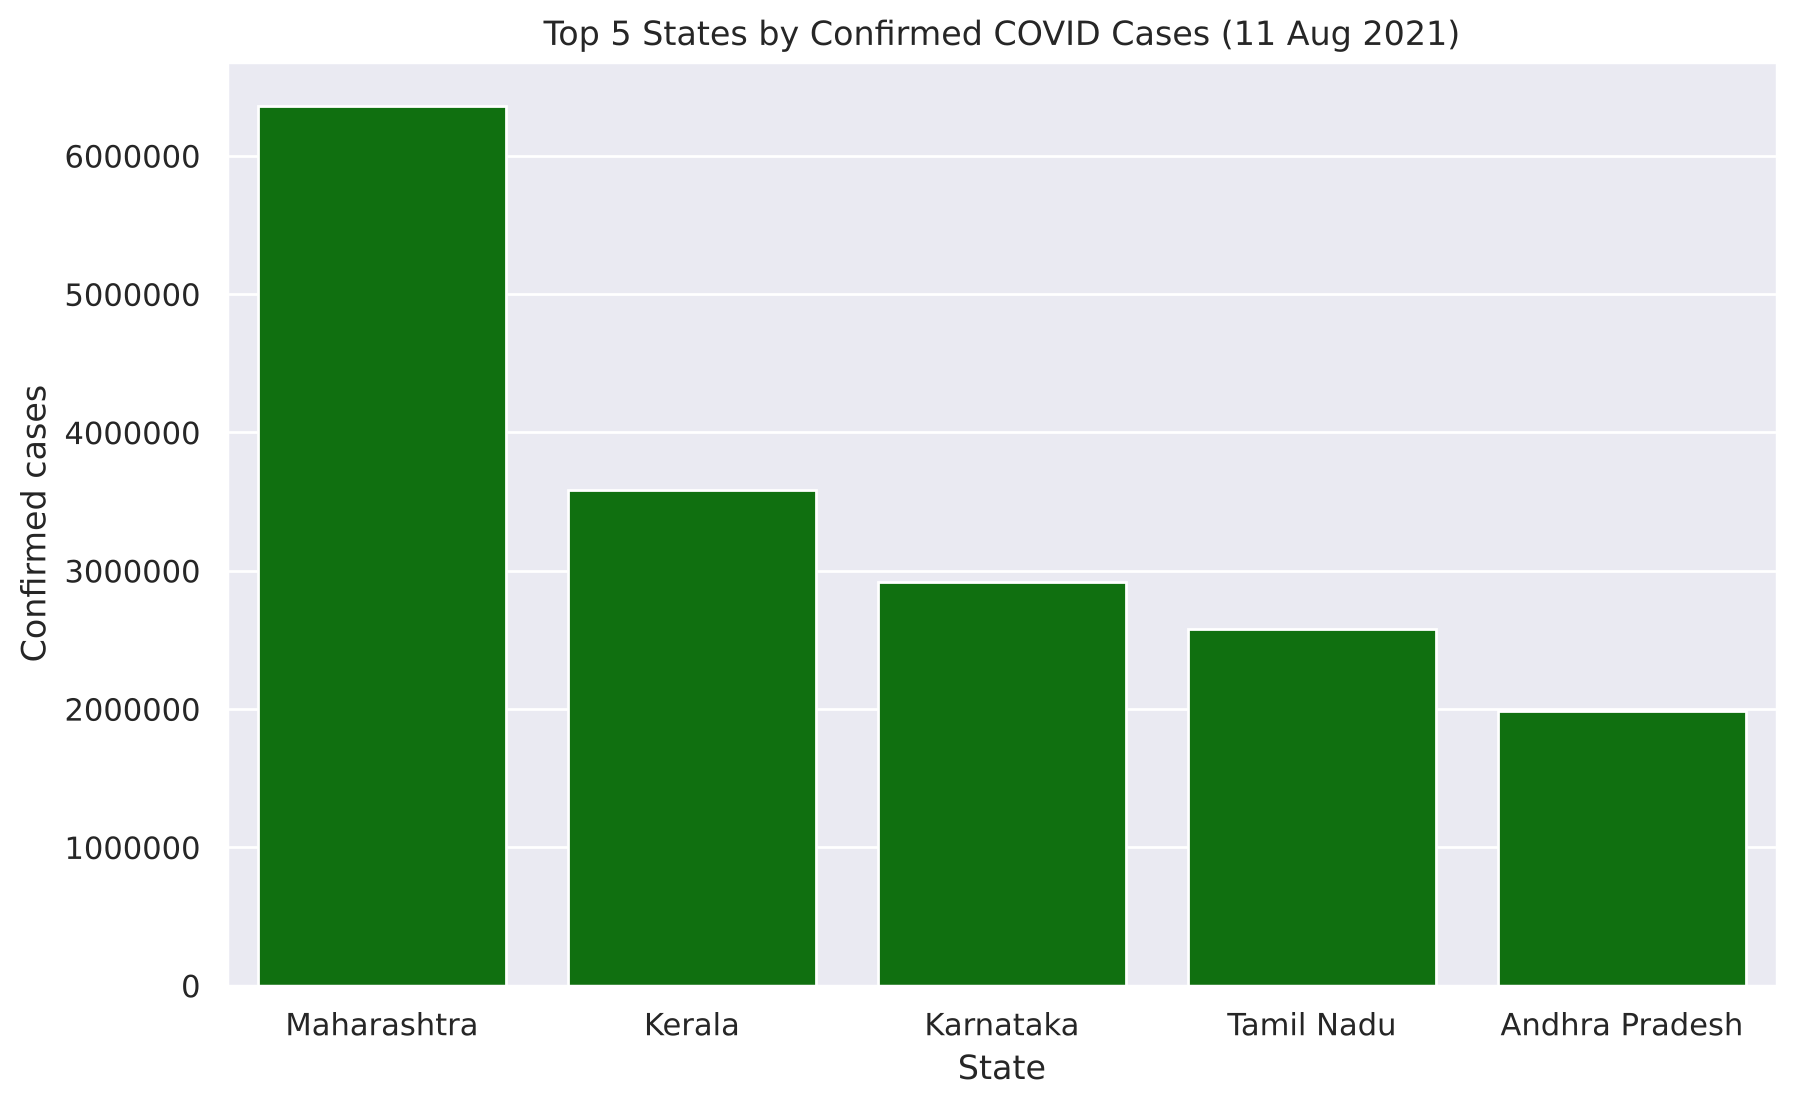

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=most_cases_states, ax=ax, x="State/UnionTerritory", y="Confirmed", color="green")

ax.set_title(f"Top 5 States by Confirmed COVID Cases ({as_of})")
ax.set_xlabel("State")
ax.set_ylabel("Confirmed cases")
ax.ticklabel_format(style="plain", axis="y")   # show 6000000 instead of 6e6

plt.savefig("../images/top5_confirmed_cases.png", bbox_inches="tight")
plt.show()

**What it shows:** Maharashtra's bar is the tallest, about 1.8 times Kerala's, which is the next state.

### Question 2: Top 5 states by deaths

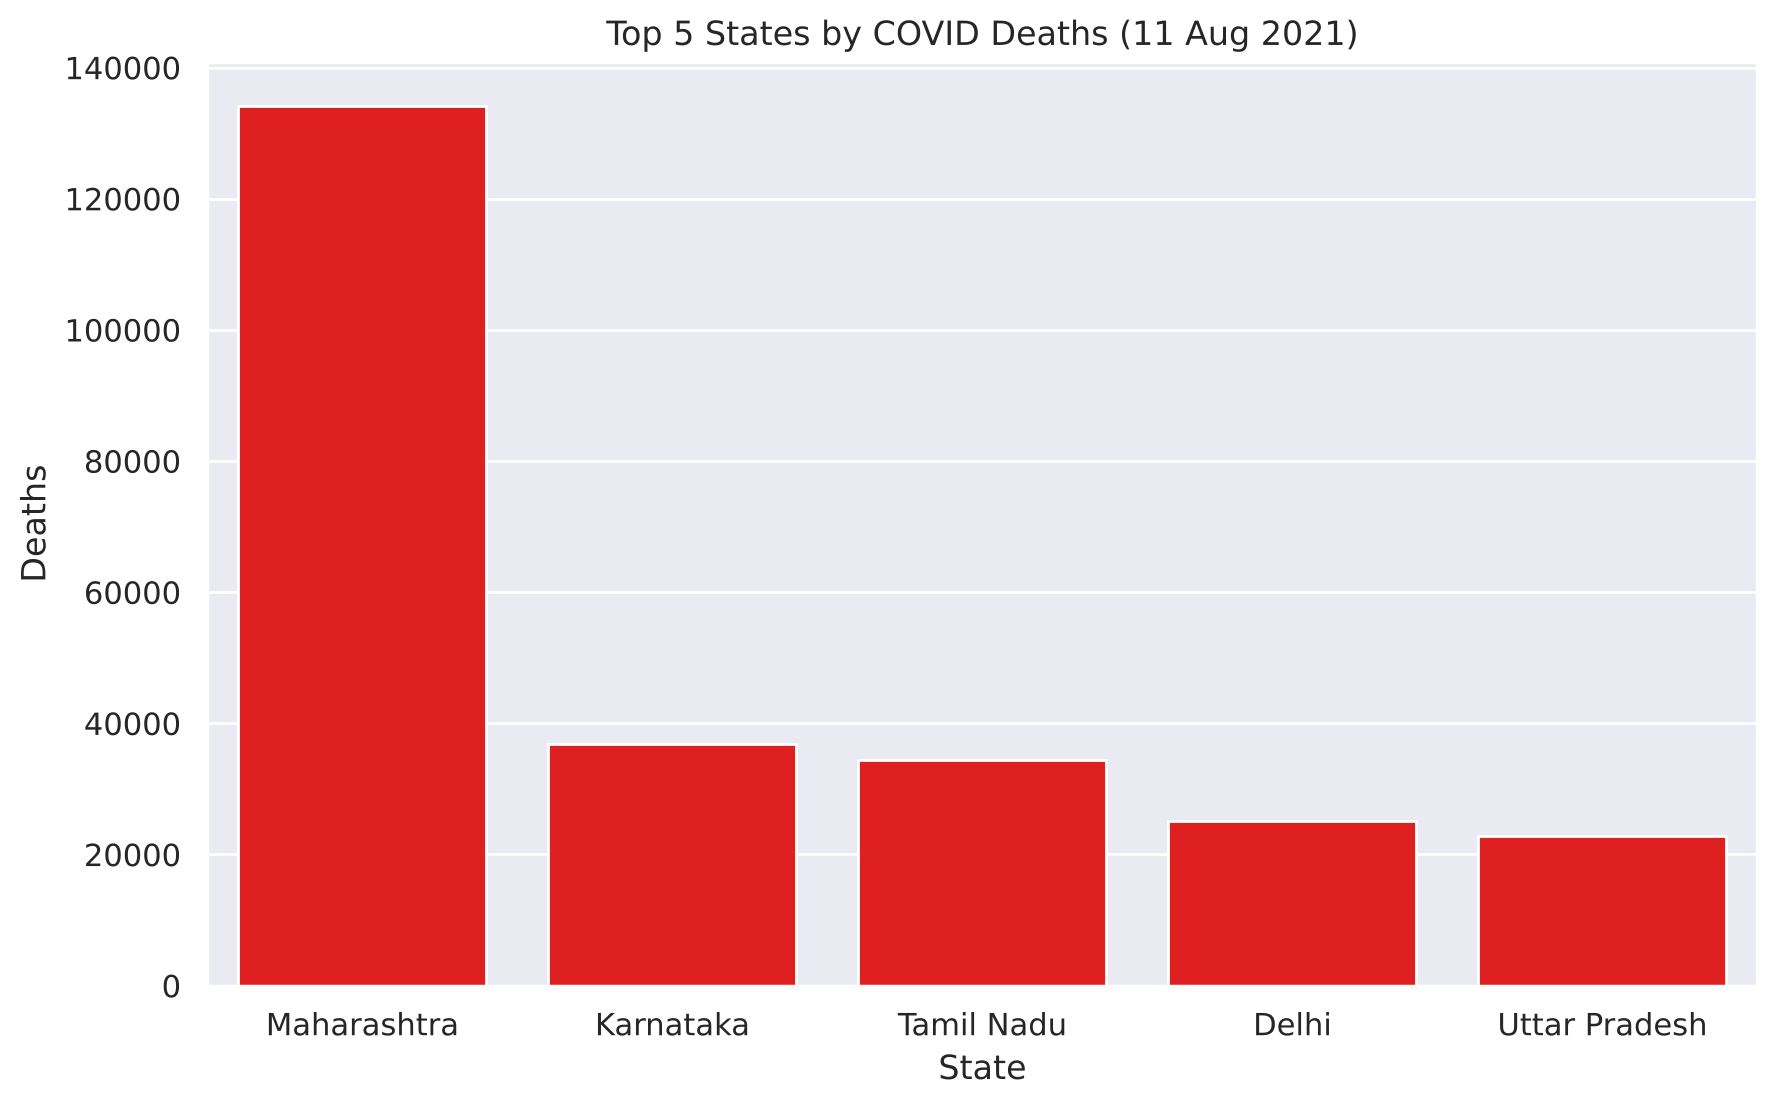

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=most_deaths_states, ax=ax, x="State/UnionTerritory", y="Deaths", color="red")

ax.set_title(f"Top 5 States by COVID Deaths ({as_of})")
ax.set_xlabel("State")
ax.set_ylabel("Deaths")

plt.savefig("../images/top5_deaths.png", bbox_inches="tight")
plt.show()

**What it shows:** Maharashtra's deaths (134,201) are more than 3.6 times Karnataka's (36,848), the next state.

### Question 3: Top 5 states by recorded death rate

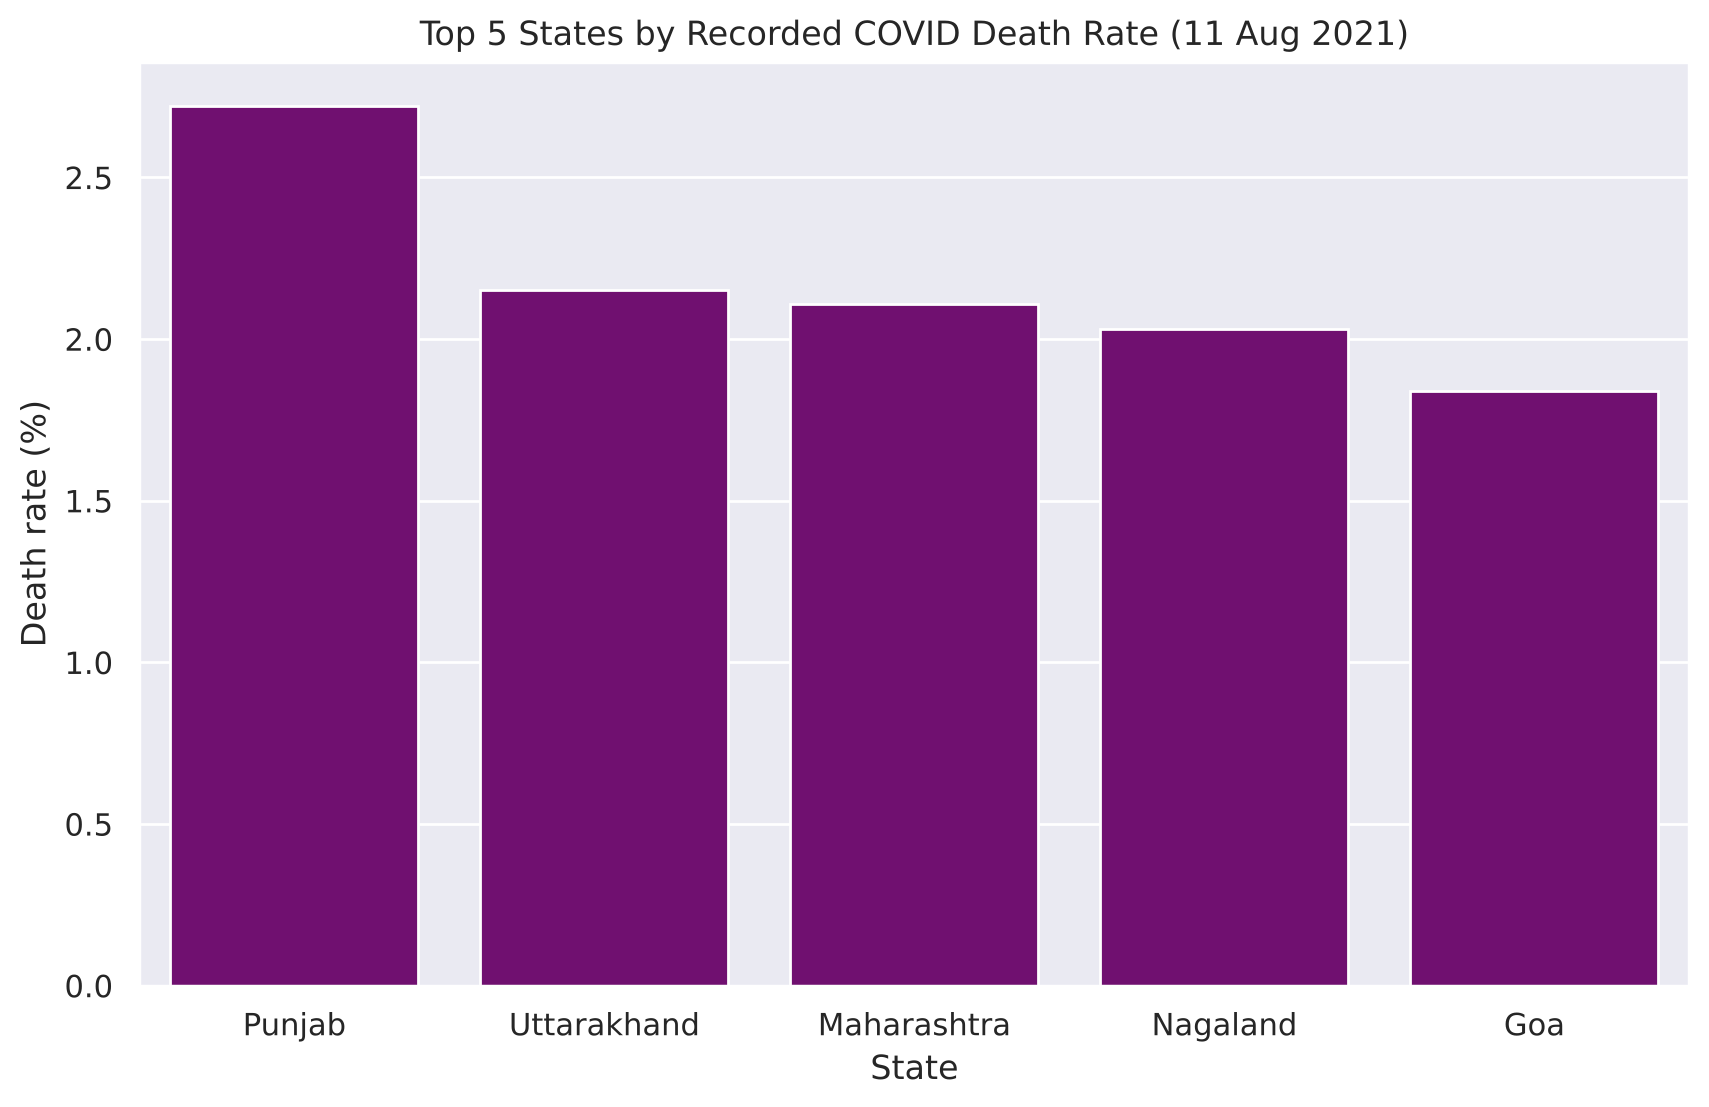

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=highest_rate_states, ax=ax, x="State/UnionTerritory", y="Death_rate", color="purple")

ax.set_title(f"Top 5 States by Recorded COVID Death Rate ({as_of})")
ax.set_xlabel("State")
ax.set_ylabel("Death rate (%)")

plt.savefig("../images/top5_death_rate.png", bbox_inches="tight")
plt.show()

**What it shows:** Punjab has the tallest bar (2.72%), ahead of Uttarakhand (2.15%) and Maharashtra (2.11%). The five bars are close together, between 1.84% and 2.72%.

### Question 4: India's daily new cases over time

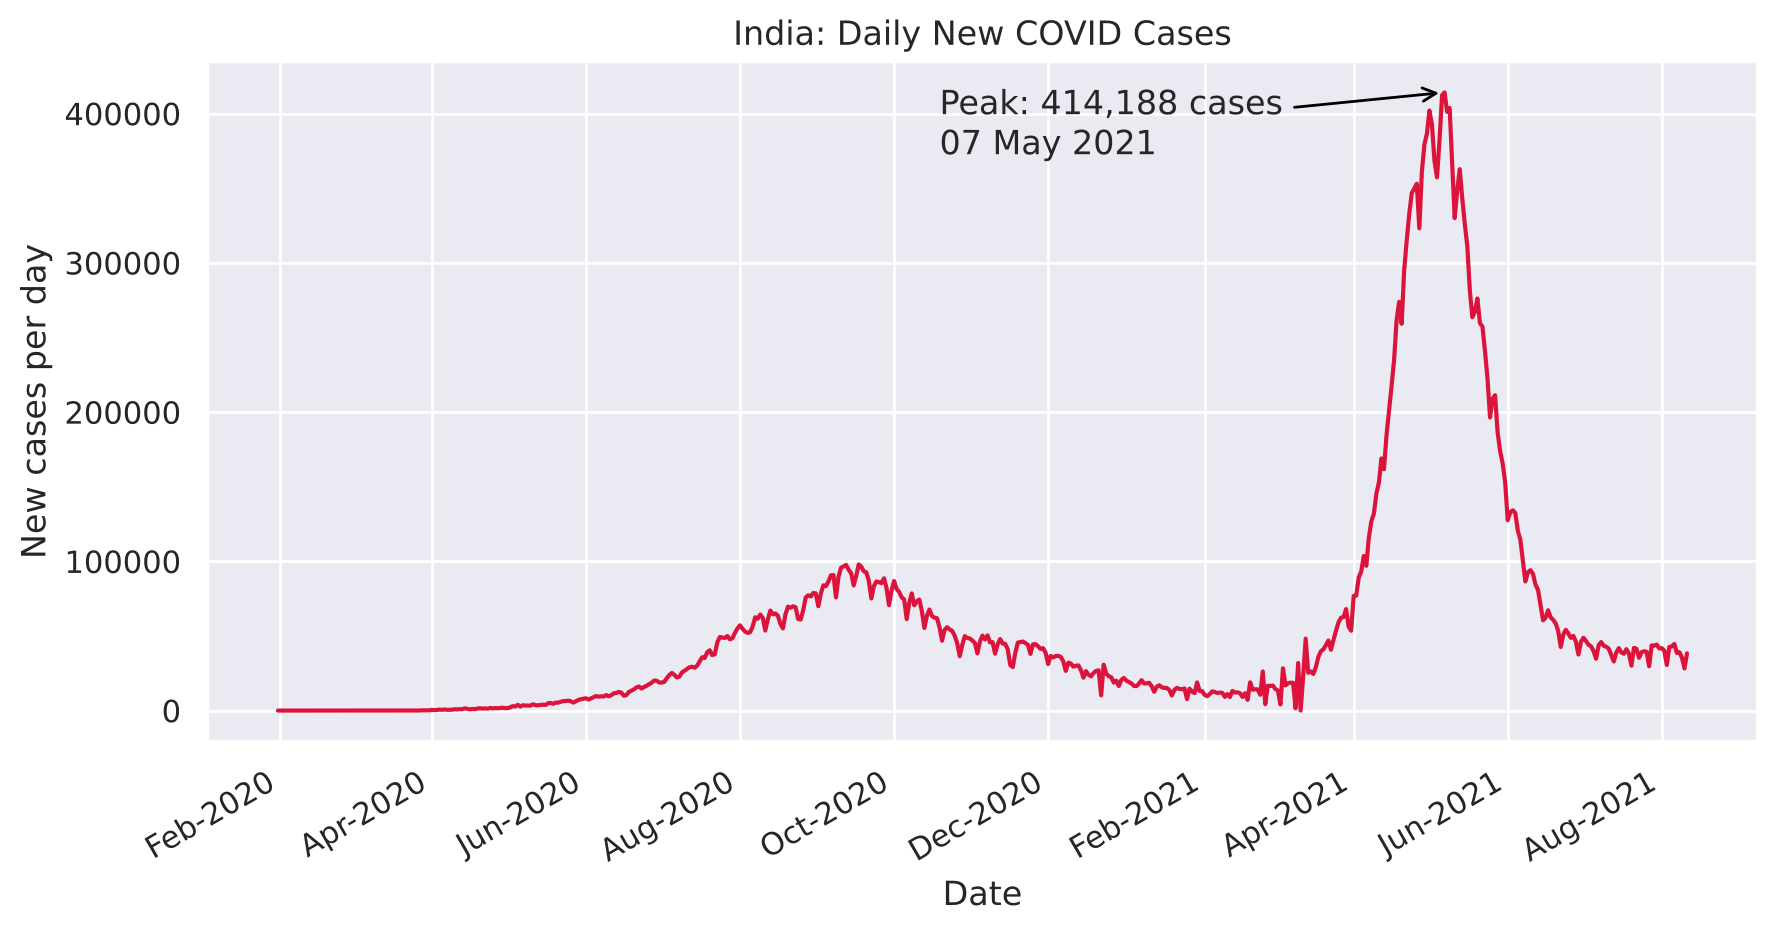

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(daily_cases.index, daily_cases.values, color="crimson")

ax.set_title("India: Daily New COVID Cases")
ax.set_xlabel("Date")
ax.set_ylabel("New cases per day")
ax.ticklabel_format(style="plain", axis="y")

# Date labels like Dec-2020, one label every 2 months
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%Y"))
fig.autofmt_xdate()

# Arrow pointing at the highest day.
# xytext puts the text 200 days to the left of the peak, so it does not cover the line.
ax.annotate(
    f"Peak: {peak_value:,.0f} cases\n{peak_date:%d %b %Y}",
    xy=(peak_date, peak_value),
    xytext=(peak_date - pd.Timedelta(days=200), peak_value * 0.9),
    arrowprops=dict(arrowstyle="->", color="black"),
)

plt.savefig("../images/india_daily_cases.png", bbox_inches="tight")
plt.show()

**What it shows:** The line has two humps. The first is small (September 2020), and the second is far taller (peak on 7 May 2021), followed by a fast drop.

## 5. Key Takeaways

1. **Maharashtra is the biggest outlier.** It has the most confirmed cases (6.36M, about 20% of India's total) and the most deaths (134,201, about 31%).
2. **Cases and deaths don't rank the same.** Kerala is #2 in cases but is not in the top 5 for deaths.
3. **Death rate tells a different story.** Punjab has the highest recorded death rate (2.72%), and Maharashtra is only #3 (2.11%).
4. **India had two waves, and the second was much bigger.** Daily cases peaked at about 98,000 on 17 Sep 2020, then hit a record of 414,188 on 7 May 2021.
5. **Limitation:** death rate depends on how many cases were detected, so these are recorded rates, not proof that a state is more dangerous.